In [63]:
# Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore') # We can suppress the warnings

In [64]:
# Load the dataset
df= pd.read_csv('student-mat.csv')

In [65]:
# Display the first five records
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [66]:
# Display the number of rows and columns
df.shape

(395, 33)

In [67]:
# Check columns
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [68]:
# Display information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [69]:
# Check missing values
df.isna().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [70]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [71]:
# Describe numerical variables
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


In [72]:
# Select categorical columns
categorical_columns = df.select_dtypes(include='object').columns
print(categorical_columns.tolist())

['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [73]:
# Describe categorical variables
df[categorical_columns].describe().T

,count,unique,top,freq
school,395,2,GP,349
sex,395,2,F,208
address,395,2,U,307
famsize,395,2,GT3,281
Pstatus,395,2,T,354
Mjob,395,5,other,141
Fjob,395,5,other,217
reason,395,4,course,145
guardian,395,3,mother,273
schoolsup,395,2,no,344


In [74]:
# Create the target column from the final grade
df['result'] = df['G3'].apply(
    lambda grade: 'Pass' if grade >= 10 else 'Fail'
)

# Convert the result labels to numbers: Pass = 0, Fail = 1
df['result'] = df['result'].replace({'Pass': 0, 'Fail': 1})

# Display the number of records in each class
print(df['result'].value_counts())

result
0    265
1    130
Name: count, dtype: int64


In [75]:
# Split the dataset into features and target
X = df.drop(columns=['G3', 'result'])
y = df['result']

# Display the shapes
print('X:', X.shape)
print('y:', y.shape)

X: (395, 32)
y: (395,)


In [76]:
# Split the data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

X.shape, y.shape, X_train.shape, X_test.shape, y_train.shape, y_test.shape

((395, 32), (395,), (296, 32), (99, 32), (296,), (99,))

In [77]:
# Identify numerical and categorical predictor columns
numeric_features = X_train.select_dtypes(include='number').columns
categorical_features = X_train.select_dtypes(include='object').columns

print('Number of numerical features:', len(numeric_features))
print('Number of categorical features:', len(categorical_features))

Number of numerical features: 15
Number of categorical features: 17


In [78]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Encode categorical features and keep numerical features unchanged
tree_preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('numeric', 'passthrough', numeric_features)
    ]
)

### Encoding categorical features
The dataset contains categorical predictor variables stored as text. These variables must be converted into a numerical format before they can be used by the machine learning models. One-Hot Encoding creates a separate binary column for each category and avoids assigning an artificial order to categories. The numerical features are kept unchanged. This preprocessing method follows the scikit-learn documentation (Scikit-learn developers, n.d.).

In [79]:
# Fit the preprocessor on the training data and transform it
X_train_encoded = tree_preprocessor.fit_transform(X_train)

# Transform the test data using the fitted preprocessor
X_test_encoded = tree_preprocessor.transform(X_test)

# Display the new shapes
print('Encoded training data:', X_train_encoded.shape)
print('Encoded test data:', X_test_encoded.shape)

Encoded training data: (296, 58)
Encoded test data: (99, 58)


### Decision Tree Classifier
A Decision Tree is used because this is a classification task: the target variable has two classes, Pass and Fail. The model learns decision rules from the predictor variables. Its maximum depth can be limited to reduce unnecessary complexity and help control overfitting.

In [80]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(max_depth = 4, random_state=42)

# Train the model using the encoded training data
dt_classifier.fit(X_train_encoded, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [81]:
# Predict the results for the test data
y_pred_dt = dt_classifier.predict(X_test_encoded)

# Display actual and predicted values side by side
results_dt = pd.DataFrame({'Actual': y_test.reset_index(drop=True),'Predicted': y_pred_dt})

print(results_dt.head(20))

    Actual  Predicted
0        0          1
1        1          1
2        0          0
3        1          1
4        1          1
5        0          0
6        0          0
7        1          1
8        0          0
9        1          1
10       1          1
11       1          1
12       0          0
13       0          0
14       0          0
15       0          0
16       0          1
17       1          1
18       1          1
19       0          0


In [82]:
# Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy, how often is the classifier correct?
print("Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred_dt)))

Accuracy: 0.91


### Decision Tree: Initial Accuracy

The Decision Tree achieved an accuracy of 0.91 on the test set. This means that it correctly classified approximately 91% of the 99 students in the test set. Accuracy gives an overall summary, but it does not show how well the model identifies each class. The confusion matrix and classification report will be used next to examine Pass and Fail predictions in more detail.

### Confusion Matrix

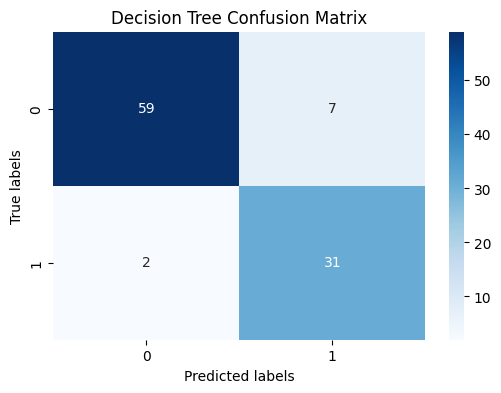

In [83]:
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

# Plot the confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Decision Tree Confusion Matrix')
plt.show()

The confusion matrix shows the Decision Tree's predictions on the 99 test cases. Class 0 represents Pass, and class 1 represents Fail. The model correctly classified 59 students who passed and 31 students who failed. It incorrectly predicted Fail for 7 students who actually passed, and predicted Pass for 2 students who actually failed. Overall, the model classified 90 out of 99 students correctly, which is consistent with an accuracy of approximately 0.91

### Classification Report

In [84]:
from sklearn.metrics import classification_report

# Display the classification report
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.97      0.89      0.93        66
           1       0.82      0.94      0.87        33

    accuracy                           0.91        99
   macro avg       0.89      0.92      0.90        99
weighted avg       0.92      0.91      0.91        99



The Decision Tree achieved an overall accuracy of 0.91 on the 99 test cases. For class 1 (Fail), the model achieved a recall of 0.94, meaning it identified 94% of students who actually failed. Its precision for this class was 0.82, meaning that 82% of students predicted as Fail were actually in that class. For class 0 (Pass), precision was 0.97 and recall was 0.89. The F1-scores were 0.93 for Pass and 0.87 for Fail, showing a reasonably balanced performance across both classes.

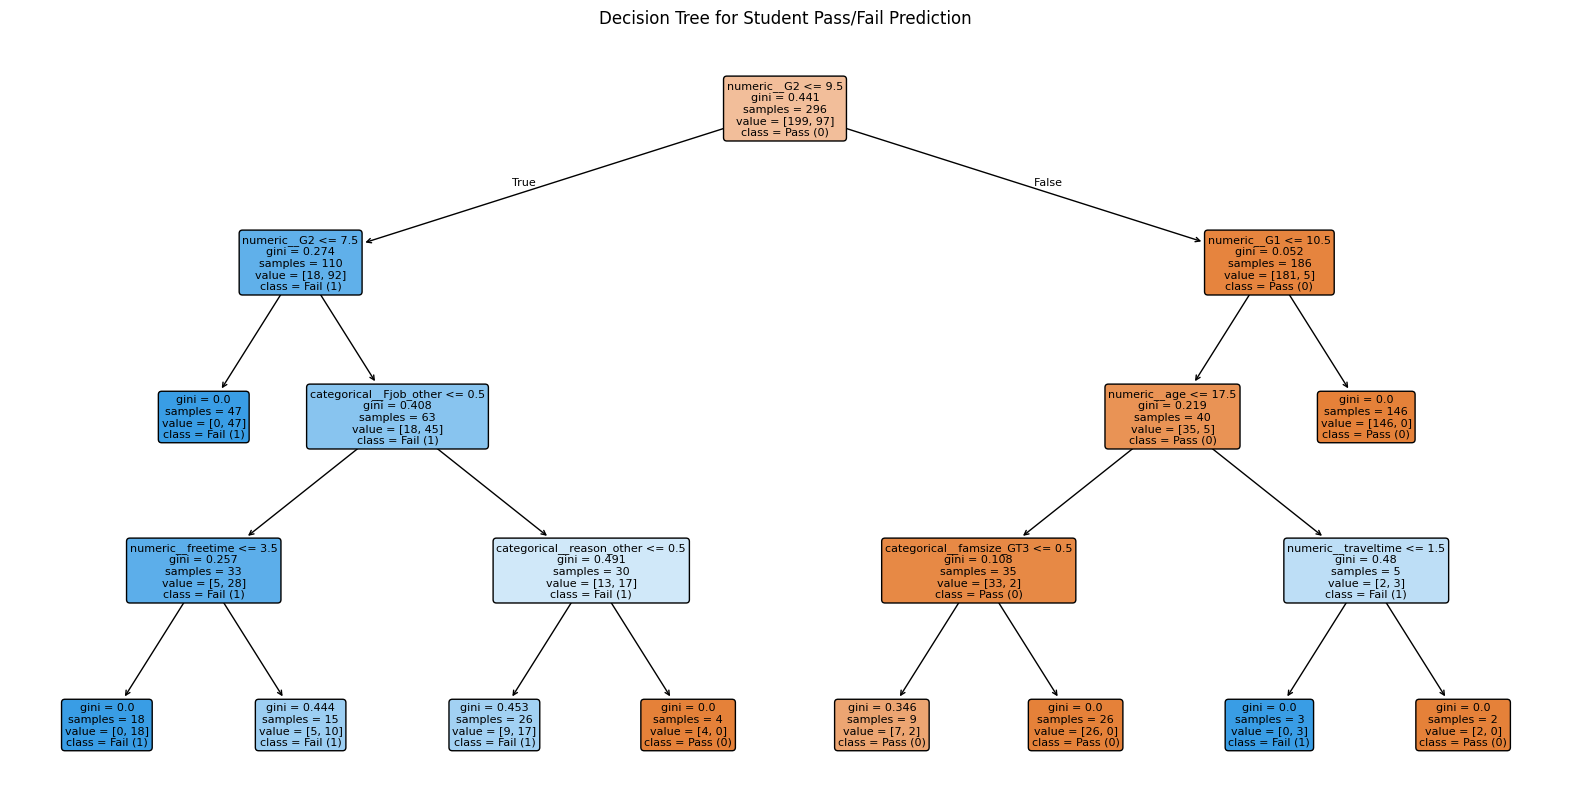

In [85]:
from sklearn.tree import plot_tree

#Plot the Decision Tree
plt.figure(figsize=(20, 10))
plot_tree(dt_classifier,filled=True,feature_names=tree_preprocessor.get_feature_names_out(),class_names=['Pass (0)', 'Fail (1)'],rounded=True,fontsize=8)
plt.title('Decision Tree for Student Pass/Fail Prediction')
plt.show()

The tree uses G2 as its first splitting feature, with a threshold of 9.5. This indicates that the previous-period grade is an important predictor of the Pass/Fail outcome in this model. Other features used in later splits include G1, age, free time, travel time, and some categorical variables.

G3 was excluded from the predictors because it was used to define the target variable. However, G2 is closely related to G3, so its strong predictive role should be considered when interpreting the results. Some terminal nodes contain only a small number of students; therefore, model performance on unseen test data is also important when assessing possible overfitting.

### Random Forest Classifier

From the class notes, I understand that Random Forest works by combining several decision trees. Each tree makes its own prediction using a random sample of the data, and the trees vote for the final result. In this assignment, the model will use that voting process to classify students as Pass or Fail.

I will compare Random Forest with the Decision Tree using the same training and test data. I will also examine the feature importance results to see which student characteristics contributed most to the predictions.

In [86]:
# Import the Random Forest Model
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest Classifier
clf_RF = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model using the training data
clf_RF.fit(X_train_encoded, y_train)

# Predict the results for the test data
y_pred_rf = clf_RF.predict(X_test_encoded)

In [87]:
# Model Accuracy, how often is the classifier correct?
print('Random Forest Accuracy:',metrics.accuracy_score(y_test, y_pred_rf))

# Rounded upto 2 decimal places
print( 'Random Forest Accuracy: {:.2f}'.format(metrics.accuracy_score(y_test, y_pred_rf)) )

Random Forest Accuracy: 0.9090909090909091
Random Forest Accuracy: 0.91


### Random Forest Confusion Matrix

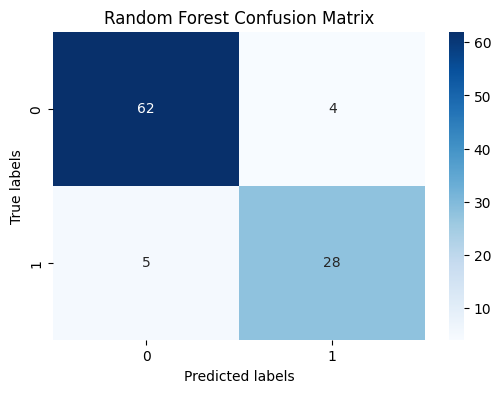

In [88]:
# Calculate the confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Plot the confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Random Forest Confusion Matrix')
plt.show()

The confusion matrix shows the Random Forest predictions on the 99 test cases. Class 0 represents Pass, and class 1 represents Fail. The model correctly classified 62 students who passed and 28 students who failed. It incorrectly predicted Fail for 4 students who actually passed, and predicted Pass for 5 students who actually failed. Overall, it classified 90 out of 99 students correctly, which is consistent with an accuracy of approximately 0.91

### Random Forest Classification Report

In [89]:
# Display the classification report
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.93      0.94      0.93        66
           1       0.88      0.85      0.86        33

    accuracy                           0.91        99
   macro avg       0.90      0.89      0.90        99
weighted avg       0.91      0.91      0.91        99



The Random Forest achieved an accuracy of 0.91 on the 99 test cases. For class 1 (Fail), the model had a precision of 0.88 and a recall of 0.85. This means that 28 of the 33 students who actually failed were identified correctly. For class 0 (Pass), the recall was 0.94, so the model correctly identified 62 of the 66 students who passed.

The Random Forest and Decision Tree achieved the same overall accuracy, but their results differ by class. The Decision Tree had a higher recall for Fail (0.94 compared with 0.85), while the Random Forest had higher precision for Fail (0.88 compared with 0.82).

### Comparison of the Models

The Decision Tree and Random Forest are compared using accuracy, precision, recall, and F1-score. These metrics are calculated from the predictions on the same test set, so their performance can be compared consistently.

In [90]:
# Store model comparison results
results = []

# Evaluate the Decision Tree
dt_report = classification_report(y_test, y_pred_dt, output_dict=True)
# Store results
results.append(['Decision Tree', metrics.accuracy_score(y_test, y_pred_dt), dt_report['weighted avg']['precision'], dt_report['weighted avg']['recall'], dt_report['weighted avg']['f1-score']])

# Evaluate the Random Forest
rf_report = classification_report(y_test, y_pred_rf, output_dict=True)
# Store results
results.append(['Random Forest', metrics.accuracy_score(y_test, y_pred_rf), rf_report['weighted avg']['precision'], rf_report['weighted avg']['recall'], rf_report['weighted avg']['f1-score']])

# Convert results to a DataFrame
results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])

print(results_df)

           Model  Accuracy  Precision    Recall  F1 Score
0  Decision Tree  0.909091   0.916739  0.909091  0.910502
1  Random Forest  0.909091   0.908582  0.909091  0.908733


The Decision Tree and Random Forest achieved the same accuracy (0.91) and weighted recall (0.91) on the test set. The Decision Tree had slightly higher weighted precision and F1-score, although the differences were small. The class-specific results also show that the models behave differently when identifying students who fail. Cross-validation will be used to assess how consistent their performance is across different data splits.

### Cross Validation

We will use 5-fold cross validation to evaluate the consistency of the Decision Tree and Random Forest.

In [91]:
from sklearn.model_selection import cross_val_score

# Cross-validation for the Decision Tree
cv_scores_dt = cross_val_score(dt_classifier, X_train_encoded, y_train, scoring='accuracy', cv=5)

print('Decision Tree CV scores:', cv_scores_dt)
print('Decision Tree Mean CV Accuracy:', cv_scores_dt.mean())

# Cross-validation for the Random Forest
cv_scores_rf = cross_val_score(clf_RF, X_train_encoded, y_train, scoring='accuracy',cv=5)

print('Random Forest CV scores:', cv_scores_rf)
print('Random Forest Mean CV Accuracy:', cv_scores_rf.mean())

Decision Tree CV scores: [0.88333333 0.89830508 0.91525424 0.93220339 0.79661017]
Decision Tree Mean CV Accuracy: 0.8851412429378531
Random Forest CV scores: [0.85       0.91525424 0.94915254 0.91525424 0.89830508]
Random Forest Mean CV Accuracy: 0.9055932203389832


We tried cross-validation with five folds for both models. The average accuracy was 0.885 for the Decision Tree and 0.906 for the Random Forest. The Random Forest got a slightly higher average score.

The scores were not the same in every fold. The Decision Tree went from 0.80 to 0.93, and the Random Forest went from 0.85 to 0.95. Cross validation is useful because it shows how the models can get different results with different parts of the training data. We will compare them again after tuning the parameters.

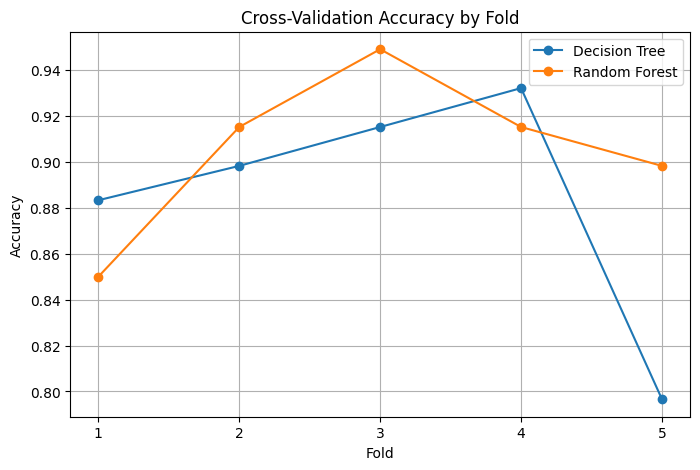

In [92]:
# Plot the cross-validation accuracy scores
folds = range(1, 6)

plt.figure(figsize=(8, 5))
plt.plot(folds, cv_scores_dt, marker='o', label='Decision Tree')
plt.plot(folds, cv_scores_rf, marker='o', label='Random Forest')

plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.title('Cross-Validation Accuracy by Fold')
plt.xticks(folds)
plt.legend()
plt.grid(True)
plt.show()

The Random Forest had a higher accuracy in three of the five folds, while the Decision Tree was higher in folds 1 and 4. The average accuracy was 0.906 for Random Forest and 0.885 for Decision Tree. The Decision Tree score dropped more in fold 5, so its results changed more across these folds

### Comparing the Models with Different Data Splits
We will compare the Decision Tree and Random Forest using test sets of 5% and 15%. 

### 5% test split

In [93]:
# Split the data into training and testing sets (5% test split)
X_train_5, X_test_5, y_train_5, y_test_5 = train_test_split(X, y, test_size=0.05, random_state=42, stratify=y)

# Display the shapes
X_train_5.shape, X_test_5.shape, y_train_5.shape, y_test_5.shape

((375, 32), (20, 32), (375,), (20,))

In [94]:
# Identify numerical and categorical features
numeric_features_5 = X_train_5.select_dtypes(include='number').columns
categorical_features_5 = X_train_5.select_dtypes(include='object').columns

print('Number of numerical features:', len(numeric_features_5))
print('Number of categorical features:', len(categorical_features_5))

Number of numerical features: 15
Number of categorical features: 17


In [95]:
# Prepare the categorical and numerical features
preprocessor_5 = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features_5),
        ('numeric', 'passthrough', numeric_features_5)
    ]
)

In [96]:
# Fit the preprocessor on training data and transform it
X_train_5_encoded = preprocessor_5.fit_transform(X_train_5)

# Transform the test data using the fitted preprocessor
X_test_5_encoded = preprocessor_5.transform(X_test_5)

# Display the shapes
X_train_5_encoded.shape, X_test_5_encoded.shape

((375, 58), (20, 58))

We split the data into training and test sets, using 5% for testing. This gave me 375 students for training and 20 for testing. We used stratify=y to keep the Pass and Fail proportions similar in both sets.

We found 15 numerical features and 17 categorical features, we used OneHotEncoder for the categorical features and kept the numerical features unchanged. The encoded data has 58 columns. We fitted the preprocessor on the training data and then used it to transform the test data. Now we can train the Decision Tree on this 5% split.

### Decision Tree with the 5% Test Split

In [97]:
# Create the Decision Tree Classifier for the 5% test split
dt_classifier_5 = DecisionTreeClassifier(max_depth=4, random_state=42)

# Train the model
dt_classifier_5.fit(X_train_5_encoded, y_train_5)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [98]:
# Predict the results for the test data
y_pred_dt_5 = dt_classifier_5.predict(X_test_5_encoded)

# Display actual and predicted values
results_dt_5 = pd.DataFrame({'Actual': y_test_5.reset_index(drop=True), 'Predicted': y_pred_dt_5})

print(results_dt_5)

    Actual  Predicted
0        1          0
1        0          0
2        0          0
3        1          1
4        1          1
5        0          0
6        0          0
7        1          1
8        1          0
9        1          0
10       0          0
11       0          0
12       0          0
13       1          1
14       0          0
15       0          0
16       0          0
17       0          0
18       0          0
19       0          0


In [99]:
# Model Accuracy, how often is the classifier correct?
print("Decision Tree Accuracy (5% test split): {:.2f}".format(metrics.accuracy_score(y_test_5, y_pred_dt_5)))

Decision Tree Accuracy (5% test split): 0.85


The Decision Tree got 17 out of the 20 predictions right, giving an accuracy of 0.85. It made three incorrect predictions. 

### Random Forest with the 5% Test Split

In [100]:
# Create the Random Forest Classifier
clf_RF_5 = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
clf_RF_5.fit(X_train_5_encoded, y_train_5)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [101]:
# Predict the results for the test data
y_pred_rf_5 = clf_RF_5.predict(X_test_5_encoded)

# Display actual and predicted values
results_rf_5 = pd.DataFrame({'Actual': y_test_5.reset_index(drop=True),'Predicted': y_pred_rf_5})

print(results_rf_5)

    Actual  Predicted
0        1          0
1        0          0
2        0          0
3        1          1
4        1          1
5        0          0
6        0          0
7        1          1
8        1          0
9        1          1
10       0          0
11       0          0
12       0          0
13       1          1
14       0          0
15       0          0
16       0          0
17       0          0
18       0          0
19       0          0


In [102]:
# Model Accuracy, how often is the classifier correct?
print("Random Forest Accuracy (5% test split): {:.2f}".format(metrics.accuracy_score(y_test_5, y_pred_rf_5)))

Random Forest Accuracy (5% test split): 0.90


The Random Forest got 18 out of 20 predictions right, giving an accuracy of 0.90. This was higher than the Decision Tree accuracy of 0.85.

### 15% test split

In [103]:
# Split the data into training and testing sets (15% test split)
X_train_15, X_test_15, y_train_15, y_test_15 = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)

# Display the shapes
X_train_15.shape, X_test_15.shape, y_train_15.shape, y_test_15.shape

((335, 32), (60, 32), (335,), (60,))

In [104]:
# Identify numerical and categorical features
numeric_features_15 = X_train_15.select_dtypes(include='number').columns
categorical_features_15 = X_train_15.select_dtypes(include='object').columns

print('Number of numerical features:', len(numeric_features_15))
print('Number of categorical features:', len(categorical_features_15))

Number of numerical features: 15
Number of categorical features: 17


In [105]:
# Prepare the categorical and numerical features
preprocessor_15 = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features_15),
        ('numeric', 'passthrough', numeric_features_15)
    ]
)

In [106]:
# Fit the preprocessor on training data and transform it
X_train_15_encoded = preprocessor_15.fit_transform(X_train_15)

# Transform the test data using the fitted preprocessor
X_test_15_encoded = preprocessor_15.transform(X_test_15)

# Display the shapes
X_train_15_encoded.shape, X_test_15_encoded.shape

((335, 58), (60, 58))

We used 15% of the data for testing. After encoding the categorical features, the training data has 335 rows and the test data has 60 rows. Both sets have 58 columns.

### Decision Tree with the 15% Test Split

In [107]:
# Create the Decision Tree Classifier
dt_classifier_15 = DecisionTreeClassifier(max_depth=4, random_state=42)

# Train the model
dt_classifier_15.fit(X_train_15_encoded, y_train_15)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [108]:
# Predict the results for the test data
y_pred_dt_15 = dt_classifier_15.predict(X_test_15_encoded)

# Display actual and predicted values
results_dt_15 = pd.DataFrame({'Actual': y_test_15.reset_index(drop=True),'Predicted': y_pred_dt_15})

print(results_dt_15)

    Actual  Predicted
0        0          0
1        0          0
2        0          0
3        0          0
4        1          0
5        0          0
6        1          1
7        1          1
8        1          1
9        0          0
10       0          0
11       1          1
12       1          1
13       0          0
14       0          0
15       1          1
16       0          0
17       0          1
18       0          0
19       0          0
20       0          0
21       1          1
22       1          1
23       0          1
24       1          1
25       1          1
26       1          0
27       1          1
28       1          1
29       0          0
30       0          0
31       1          0
32       1          1
33       0          0
34       0          0
35       0          0
36       0          0
37       0          0
38       0          0
39       0          0
40       1          1
41       0          0
42       0          0
43       0          1
44       0

In [109]:
# Model Accuracy, how often is the classifier correct?
print("Decision Tree Accuracy (15% test split): {:.2f}".format(metrics.accuracy_score(y_test_15, y_pred_dt_15)))

Decision Tree Accuracy (15% test split): 0.87


The Decision Tree got 52 out of 60 predictions right, giving an accuracy of 0.87. It made eight incorrect predictions.

### Random Forest with the 15% Test Split

In [110]:
# Create the Random Forest Classifier
clf_RF_15 = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
clf_RF_15.fit(X_train_15_encoded, y_train_15)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [111]:
# Predict the results for the test data
y_pred_rf_15 = clf_RF_15.predict(X_test_15_encoded)

# Display actual and predicted values
results_rf_15 = pd.DataFrame({'Actual': y_test_15.reset_index(drop=True),'Predicted': y_pred_rf_15})

print(results_rf_15)

    Actual  Predicted
0        0          0
1        0          0
2        0          0
3        0          0
4        1          1
5        0          0
6        1          0
7        1          1
8        1          1
9        0          0
10       0          0
11       1          1
12       1          1
13       0          0
14       0          0
15       1          1
16       0          0
17       0          1
18       0          0
19       0          0
20       0          0
21       1          1
22       1          1
23       0          0
24       1          1
25       1          1
26       1          0
27       1          1
28       1          1
29       0          0
30       0          0
31       1          0
32       1          1
33       0          0
34       0          0
35       0          0
36       0          0
37       0          0
38       0          0
39       0          0
40       1          1
41       0          0
42       0          0
43       0          1
44       0

In [112]:
# Model Accuracy, how often is the classifier correct?
print("Random Forest Accuracy (15% test split): {:.2f}".format(metrics.accuracy_score(y_test_15, y_pred_rf_15)))

Random Forest Accuracy (15% test split): 0.90


The Random Forest got 54 out of 60 predictions right, giving an accuracy of 0.90. This was higher than the Decision Tree accuracy of 0.87.

In [113]:
# Store the accuracy results
results = [['Decision Tree', 0.85, 0.87, 0.91],['Random Forest', 0.90, 0.90, 0.91]]

# Create a DataFrame to display the results
split_results_df = pd.DataFrame(results, columns=['Model', '5% Test Split', '15% Test Split', '25% Test Split'])

print(split_results_df)

           Model  5% Test Split  15% Test Split  25% Test Split
0  Decision Tree           0.85            0.87            0.91
1  Random Forest           0.90            0.90            0.91


### Results with Different Test Splits

The Decision Tree accuracy was 0.85 with the 5% test split, 0.87 with the 15% split, and 0.91 with the 25% split. The Random Forest results were 0.90, 0.90, and 0.91. In these results, Random Forest had a higher accuracy with the 5% and 15% splits, and both models had the same accuracy with the 25% split.

### Hyperparameter tuning on the 25% test split
The earlier cells already train and compare Decision Tree and Random Forest classifiers. This section uses the same 25% test split and searches a small set of settings for those two models. GridSearchCV fits each setting with five-fold cross-validation on the encoded training data and selects the setting with the highest mean validation accuracy. The test set is used only after the search to check the selected models.

For Decision Tree, max_depth controls tree size and min_samples_leaf limits how small a leaf can be. For Random Forest, n_estimators sets the number of trees and max_depth limits their depth. The parameter choices are intentionally short so the search remains easy to follow.

In [114]:
from sklearn.model_selection import GridSearchCV

# Settings to try for each existing classification model.
param_grid = {
    'Decision Tree': {
        'max_depth': [None, 3, 4, 5, 6, 10],
        'min_samples_leaf': [1, 3, 5]
    },
    'Random Forest': {
        'n_estimators': [25, 50, 100, 200],
        'max_depth': [None, 5, 10]
    }
}

models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

# Search only the training set, then evaluate the best model on the test set.
tuning_results = []

for name, model in models.items():
    grid_search = GridSearchCV(
        model, param_grid[name], cv=5, scoring='accuracy'
    )
    grid_search.fit(X_train_encoded, y_train)

    best_params = grid_search.best_params_
    best_cv_score = grid_search.best_score_
    test_predictions = grid_search.predict(X_test_encoded)
    test_accuracy = metrics.accuracy_score(y_test, test_predictions)

    tuning_results.append([name, best_params, best_cv_score, test_accuracy])

tuning_results_df = pd.DataFrame(
    tuning_results,
    columns=['Model', 'Best Parameters', 'Best CV Accuracy', 'Test Accuracy']
)

print('Best hyperparameters and scores from GridSearchCV:')
print(tuning_results_df.to_string(index=False))

Best hyperparameters and scores from GridSearchCV:
        Model                         Best Parameters  Best CV Accuracy  Test Accuracy
Decision Tree {'max_depth': 3, 'min_samples_leaf': 1}          0.919040       0.898990
Random Forest  {'max_depth': 10, 'n_estimators': 100}          0.912316       0.919192


### Hyperparameter tuning results
On the 25% split, the Decision Tree's best settings were max_depth = 3 and min_samples_leaf = 1. Its mean five-fold validation accuracy was 0.919, and its accuracy on the 99 test students was 0.899.

The Random Forest's best settings were max_depth = 10 and n_estimators = 100. Its mean five-fold validation accuracy was 0.912, and its test accuracy was 0.919. The tree ranked slightly higher during cross-validation, while the forest classified two more students correctly on this particular test set. These small differences should be considered alongside the variation across splits already shown earlier in the notebook.